In [20]:
import pandas as pd
import numpy as np

In [21]:
# SFMS
slope = 0.86
intercept=-8.5
def del_SFMS(Mstar, SFR):
    SFMS = slope * Mstar + intercept
    del_SFMS = SFR - SFMS
    return del_SFMS

def is_quenched(del_SFMS):
    if del_SFMS < -0.5:
        return True
    else:
        return False

In [22]:
low_mass_central_df = pd.read_parquet ('../../data/low_mass_central_df_annuli_revised.parquet')

In [23]:
high_mass_central_df = pd.read_parquet ('../../data/high_mass_central_df_annuli_revised.parquet')

In [24]:

all_centrals_df = pd.concat([low_mass_central_df, high_mass_central_df], ignore_index=True)
print(f"Combined dataframe has {len(all_centrals_df)} rows.")
# --- remove quenched galaxies using del_SFMS and is_quenched ---
# del_SFMS takes (log Mstar, log SFR); 's_mass' is in 1e10 Msun and 'global_SFRs' in Msun/yr, so convert to log10 first
all_centrals_df['del_SFMS'] = del_SFMS(np.log10(all_centrals_df['s_mass'] * 1e10), np.log10(all_centrals_df['global_SFRs']))

# is_quenched expects the del_SFMS value
quenched_mask = all_centrals_df['del_SFMS'].apply(is_quenched)
removed = quenched_mask.sum()
all_centrals_df = all_centrals_df[~quenched_mask].reset_index(drop=True)
print(f"Removed {removed} quenched rows; remaining {len(all_centrals_df)} rows.")

# drop helper column
all_centrals_df = all_centrals_df.drop(columns=['del_SFMS'])
print(f"filtered dataframe has {len(all_centrals_df)} rows.")

Combined dataframe has 48576 rows.
Removed 21619 quenched rows; remaining 26957 rows.
filtered dataframe has 26957 rows.


In [25]:
all_centrals_df

,subID,bin_radii,avg_s_mass,avg_SFR,avg_gas_mass,quenching_vector,gas_mass,s_mass,BHMass,class,veldisp,global_SFRs,BH_cumQM,BH_cumRM,Mhalo,overdens,bulge,Bfld,BH_AGN,GrNr
0,312415.0,0.071176,8.105450,-3.995854,7.655353,1,0.0,0.509563,0.001050,0,64.871277,0.295028,0.000000,9.881313e-324,980.833740,45.328607,0.155899,0.125910,9.881313e-324,180
1,312415.0,0.213527,8.175151,-3.359508,7.247262,0,0.0,0.509563,0.001050,0,64.871277,0.295028,0.000000,9.881313e-324,980.833740,45.328607,0.155899,0.125910,9.881313e-324,180
2,312415.0,0.355879,7.912692,-2.209567,6.888073,0,0.0,0.509563,0.001050,0,64.871277,0.295028,0.000000,9.881313e-324,980.833740,45.328607,0.155899,0.125910,9.881313e-324,180
3,312415.0,0.498230,7.599713,-4.369588,6.704756,1,0.0,0.509563,0.001050,0,64.871277,0.295028,0.000000,9.881313e-324,980.833740,45.328607,0.155899,0.125910,9.881313e-324,180
4,312415.0,0.640582,7.371823,-4.605686,6.710869,1,0.0,0.509563,0.001050,0,64.871277,0.295028,0.000000,9.881313e-324,980.833740,45.328607,0.155899,0.125910,9.881313e-324,180
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26952,562410.0,0.479855,9.000431,-0.823600,8.259158,0,0.0,2.275262,0.004635,0,82.065796,1.607175,2461.513184,1.389233e-316,34.545956,4.056387,-0.793238,0.072292,2.461513e+03,4058
26953,562410.0,0.799758,8.623288,-1.400687,7.929631,0,0.0,2.275262,0.004635,0,82.065796,1.607175,2461.513184,1.389233e-316,34.545956,4.056387,-0.793238,0.072292,2.461513e+03,4058
26954,562410.0,1.119661,8.413935,-1.564219,7.630833,0,0.0,2.275262,0.004635,0,82.065796,1.607175,2461.513184,1.389233e-316,34.545956,4.056387,-0.793238,0.072292,2.461513e+03,4058
26955,562410.0,1.439564,8.239394,-2.031924,7.606252,0,0.0,2.275262,0.004635,0,82.065796,1.607175,2461.513184,1.389233e-316,34.545956,4.056387,-0.793238,0.072292,2.461513e+03,4058


In [26]:
# # calculating star forming efficiency (SFE) and gas fraction 
# low_mass_satellite_df['SFE'] = 10**(low_mass_satellite_df['avg_SFR'] - low_mass_satellite_df['avg_gas_mass'])
# low_mass_satellite_df['f_gas'] = 10**(low_mass_satellite_df['avg_gas_mass'] - low_mass_satellite_df['avg_s_mass'])

In [27]:
# # remove the rows where the sfr_indicator is 0.0 -> implies artificially imposed minimum
# low_mass_satellite_df = low_mass_satellite_df[low_mass_satellite_df['sfr_indicator'] != 0.0]
# low_mass_satellite_df

In [28]:
# star forming quenching vector value = 0
all_centrals_df = all_centrals_df[all_centrals_df['quenching_vector'] != 1]
all_centrals_df

,subID,bin_radii,avg_s_mass,avg_SFR,avg_gas_mass,quenching_vector,gas_mass,s_mass,BHMass,class,veldisp,global_SFRs,BH_cumQM,BH_cumRM,Mhalo,overdens,bulge,Bfld,BH_AGN,GrNr
1,312415.0,0.213527,8.175151,-3.359508,7.247262,0,0.0,0.509563,0.001050,0,64.871277,0.295028,0.000000,9.881313e-324,980.833740,45.328607,0.155899,0.125910,9.881313e-324,180
2,312415.0,0.355879,7.912692,-2.209567,6.888073,0,0.0,0.509563,0.001050,0,64.871277,0.295028,0.000000,9.881313e-324,980.833740,45.328607,0.155899,0.125910,9.881313e-324,180
6,312415.0,0.925285,7.054781,-4.070769,6.963181,0,0.0,0.509563,0.001050,0,64.871277,0.295028,0.000000,9.881313e-324,980.833740,45.328607,0.155899,0.125910,9.881313e-324,180
7,312415.0,1.067636,6.900457,-3.289078,7.173378,0,0.0,0.509563,0.001050,0,64.871277,0.295028,0.000000,9.881313e-324,980.833740,45.328607,0.155899,0.125910,9.881313e-324,180
8,312415.0,1.209988,6.796739,-2.832557,7.367570,0,0.0,0.509563,0.001050,0,64.871277,0.295028,0.000000,9.881313e-324,980.833740,45.328607,0.155899,0.125910,9.881313e-324,180
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26952,562410.0,0.479855,9.000431,-0.823600,8.259158,0,0.0,2.275262,0.004635,0,82.065796,1.607175,2461.513184,1.389233e-316,34.545956,4.056387,-0.793238,0.072292,2.461513e+03,4058
26953,562410.0,0.799758,8.623288,-1.400687,7.929631,0,0.0,2.275262,0.004635,0,82.065796,1.607175,2461.513184,1.389233e-316,34.545956,4.056387,-0.793238,0.072292,2.461513e+03,4058
26954,562410.0,1.119661,8.413935,-1.564219,7.630833,0,0.0,2.275262,0.004635,0,82.065796,1.607175,2461.513184,1.389233e-316,34.545956,4.056387,-0.793238,0.072292,2.461513e+03,4058
26955,562410.0,1.439564,8.239394,-2.031924,7.606252,0,0.0,2.275262,0.004635,0,82.065796,1.607175,2461.513184,1.389233e-316,34.545956,4.056387,-0.793238,0.072292,2.461513e+03,4058


In [29]:
all_centrals_df.shape

(23994, 20)

In [30]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import RobustScaler

# 'BHMass', 'BHCum_QM', 'Mhalo', and 'overdens' are the features wer are testing
all_centrals_df = all_centrals_df.drop(columns=["class", "BH_cumQM", "BH_cumRM", "global_SFRs", "gas_mass","avg_gas_mass", "quenching_vector", "Bfld", "veldisp", "BH_AGN","bulge"])

<Axes: >

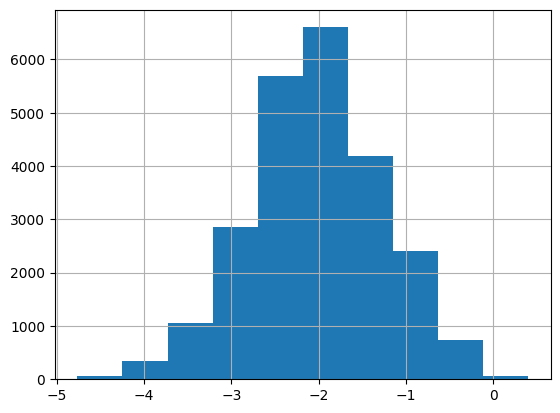

In [31]:
all_centrals_df['avg_SFR'].hist()

In [32]:
# this indicates that there are more instances of the delta rate on the left

In [33]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import RobustScaler
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold

feature_importances_list = []
feature_names = None
test_mses = []
train_mses = []


for seed in range(10):
    # split halos (GrNr) into 50% training and 50% testing, so galaxies from the same halo never span train and test
    unique_halos = np.unique(all_centrals_df['GrNr'])
    train_galaxies, test_galaxies = train_test_split(unique_halos, test_size=0.5, random_state=seed)

    # assign galaxies based on halo split
    train_data = all_centrals_df[all_centrals_df['GrNr'].isin(train_galaxies)]
    test_data = all_centrals_df[all_centrals_df['GrNr'].isin(test_galaxies)]

    X_train, y_train = train_data.drop(columns=['avg_SFR', 'subID', 'GrNr']), train_data['avg_SFR']
    X_test, y_test = test_data.drop(columns=['avg_SFR', 'subID', 'GrNr']), test_data['avg_SFR']
    
    
    if feature_names is None:
        feature_names = X_train.columns.tolist()

    scaler = RobustScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    param_grid = {
    'n_estimators': [100,200, 300, 400, 500],  
    'max_depth': [50, 100, 150, 200, 250],  
    'min_samples_split': [50, 100, 150],  
    'min_samples_leaf': [300, 400, 500, 600],  
    'max_features': [None], 
    'bootstrap': [True],
    }
    rf_regressor = RandomForestRegressor(random_state=seed, n_jobs=-1)
    groups_train = train_data['GrNr']
    cv = GroupKFold(n_splits=5)

    random_search = RandomizedSearchCV(
    estimator=rf_regressor, 
    param_distributions=param_grid, 
    n_iter=10,
    cv=cv, 
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    random_state=seed,
    verbose=2)

    random_search.fit(X_train_scaled, y_train, groups=groups_train)

    best_rf_regressor = random_search.best_estimator_

    best_rf_regressor.fit(X_train_scaled, y_train)
    
    y_train_pred = best_rf_regressor.predict(X_train_scaled)
    y_test_pred = best_rf_regressor.predict(X_test_scaled)
    
    train_mse = mean_squared_error(y_train, y_train_pred)
    test_mse = mean_squared_error(y_test, y_test_pred)
    
    train_mses.append(train_mse)
    test_mses.append(test_mse)
    
    feature_importances_list.append(best_rf_regressor.feature_importances_)
#     print(random_search.best_params_)
    print(f"Run {seed+1}: Train MSE = {train_mse:.4f}, Test MSE = {test_mse:.4f}")

print("\nAverage MSE over 10 runs:")
print(f"Train MSE: Mean = {np.mean(train_mses):.4f}, Std = {np.std(train_mses):.4f}")
print(f"Test MSE:  Mean = {np.mean(test_mses):.4f}, Std = {np.std(test_mses):.4f}")


Fitting 5 folds for each of 10 candidates, totalling 50 fits
Run 1: Train MSE = 0.2491, Test MSE = 0.2620
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Run 2: Train MSE = 0.2514, Test MSE = 0.2585
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Run 3: Train MSE = 0.2546, Test MSE = 0.2556
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Run 4: Train MSE = 0.2589, Test MSE = 0.2503
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Run 5: Train MSE = 0.2533, Test MSE = 0.2561
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Run 6: Train MSE = 0.2553, Test MSE = 0.2559
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Run 7: Train MSE = 0.2573, Test MSE = 0.2524
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Run 8: Train MSE = 0.2551, Test MSE = 0.2541
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Run 9: Train MSE = 0.2515, Test MSE = 0.2580
Fitting 5 folds for each of 10 candidates, tot


=== Average Feature Importances ===
      Feature  Mean Importance   Std Dev
1  avg_s_mass         0.968847  0.002398
0   bin_radii         0.019996  0.002142
3      BHMass         0.007173  0.002023
2      s_mass         0.003139  0.000691
4       Mhalo         0.000457  0.000232
5    overdens         0.000388  0.000370


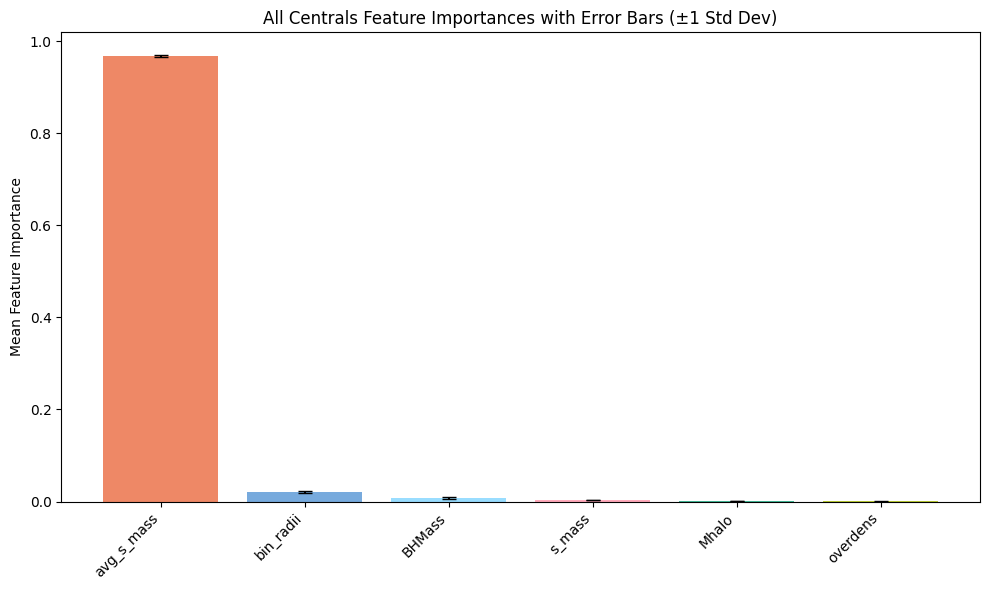

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
feature_colors = {
    'bin_radii': '#77AADD',
    'avg_s_mass': '#EE8866',
    's_mass': '#FFAABB',
    'BHMass': '#99DDFF',
    'Mhalo': '#44BB99',
    'overdens': '#BBCC33',
    'bulge': '#AAAA00',
    'BH_AGN': '#DDDDDD',
}

# importances + stds across 10 runs
importances_array = np.array(feature_importances_list)
importance_means = np.mean(importances_array, axis=0)
importance_stds = np.std(importances_array, axis=0)

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Mean Importance': importance_means,
    'Std Dev': importance_stds
}).sort_values(by='Mean Importance', ascending=False)

print("\n=== Average Feature Importances ===")
print(importance_df)

colors = [feature_colors[feat] for feat in importance_df['Feature']]
# Plot
plt.figure(figsize=(10, 6))
plt.bar(importance_df['Feature'], importance_df['Mean Importance'], yerr=importance_df['Std Dev'], capsize=5, color=colors)
plt.xticks(rotation=45, ha='right')
plt.ylabel("Mean Feature Importance")
plt.title("All Centrals Feature Importances with Error Bars (±1 Std Dev)")
plt.tight_layout()
plt.show()

In [35]:
all_centrals_df.corr()

,subID,bin_radii,avg_s_mass,avg_SFR,s_mass,BHMass,Mhalo,overdens,GrNr
subID,1.000000,-0.021009,-0.279563,-0.157772,-0.693463,-0.685959,-0.492628,-0.257422,0.825388
bin_radii,-0.021009,1.000000,-0.766746,-0.511438,0.012809,0.013557,0.005695,0.001289,-0.006857
avg_s_mass,-0.279563,-0.766746,1.000000,0.728603,0.141230,0.129540,0.078678,0.058845,-0.322191
avg_SFR,-0.157772,-0.511438,0.728603,1.000000,0.048251,0.040451,0.032839,0.045081,-0.222733
s_mass,-0.693463,0.012809,0.141230,0.048251,1.000000,0.982143,0.871442,0.605447,-0.301846
BHMass,-0.685959,0.013557,0.129540,0.040451,0.982143,1.000000,0.868157,0.583413,-0.288076
Mhalo,-0.492628,0.005695,0.078678,0.032839,0.871442,0.868157,1.000000,0.873956,-0.160858
overdens,-0.257422,0.001289,0.058845,0.045081,0.605447,0.583413,0.873956,1.000000,-0.061818
GrNr,0.825388,-0.006857,-0.322191,-0.222733,-0.301846,-0.288076,-0.160858,-0.061818,1.000000


In [36]:
import os
# Define your directory and file name
directory = 'rf_regression_outputs'
filename = 'all_centrals_rf_reg_halosplit.csv'
filepath = os.path.join(directory, filename)

# Create the directory if it doesn't exist
os.makedirs(directory, exist_ok=True)

# Save the DataFrame
importance_df.to_csv(filepath, index=False)

print(f'DataFrame saved to {filepath}')

DataFrame saved to rf_regression_outputs\all_centrals_rf_reg_halosplit.csv


In [37]:
train_mean = round(np.mean(train_mses), 2)
test_mean = round(np.mean(test_mses), 2)

df = pd.DataFrame({
    'Train MSE': [train_mean],
    'Test MSE': [test_mean]
})

print(df)
import os
# Define your directory and file name
directory = 'rf_regression_outputs'
filename = 'all_centrals_rf_reg_mse_halosplit.csv'
filepath = os.path.join(directory, filename)

# Create the directory if it doesn't exist
os.makedirs(directory, exist_ok=True)

# Save the DataFrame
df.to_csv(filepath, index=False)

print(f'DataFrame saved to {filepath}')

   Train MSE  Test MSE
0       0.25      0.26
DataFrame saved to rf_regression_outputs\all_centrals_rf_reg_mse_halosplit.csv


In [38]:
#compare MSE to variance of the target variable (avg_SFR)
mse_mean = np.mean(test_mses)
target_std = all_centrals_df['avg_SFR'].std()
target_var = all_centrals_df['avg_SFR'].var()
print(f"Mean Test MSE: {mse_mean:.4f}")
print(f"Standard Deviation of avg_SFR: {target_std:.4f}")
print(f"Variance of avg_SFR: {target_var:.4f}")

Mean Test MSE: 0.2560
Standard Deviation of avg_SFR: 0.7624
Variance of avg_SFR: 0.5813
